# Phase 1 — BM25 baseline RAG

The first system: the question goes to BM25 over the shared 66,635-paragraph corpus, the
top K paragraphs go to the LLM, and the LLM answers with citations. Every choice here was
preregistered (`PREREGISTRATION.md`, Phase 1 and amendment A1) before its results existed.

**Data used here.**

- `tune` (500 validation questions): the BM25 configuration and retrieval curves, no LLM.
- `dev` (100 validation questions): every LLM result.

The blind test splits are not loaded. This notebook only reads results written by
`run_eval.py`; nothing here retrieves or generates.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import data
import hops
import metrics
import retrieval

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6})


def read_jsonl(path):
    with open(path) as f:
        return [json.loads(line) for line in f]


def read_manifest(path):
    with open(path + ".manifest.json") as f:
        return json.load(f)


tune = data.load_split("tune")
tune_ctx = data.load_contexts("tune")
grid = json.load(open("results/tune/bm25_grid.json"))
ret = {r["qid"]: r for r in read_jsonl("results/tune/bm25_selected_retrieval.jsonl")}
print(f"tune: {len(tune)} questions; grid candidates: {len(grid['rows'])}; retrieval rows: {len(ret)}")

tune: 500 questions; grid candidates: 12; retrieval rows: 500


## 1. Choosing the BM25 configuration (`tune`, retrieval only)

Twelve candidates, in the preregistered preference order: stemming on or off, stop words
removed or kept, and three `(k1, b)` settings. Each is scored by the mean of Joint
Recall@3, @5 and @10: the share of questions whose **both** gold paragraphs are in the
top K, on exact paragraph variants. Every candidate within 0.02 of the best forms the
plateau, and the first plateau member in preference order is selected.

In [2]:
g = pd.DataFrame(grid["rows"]).set_index("preference")
g["in plateau"] = g["config"].isin(grid["plateau"])
g["selected"] = g["config"] == grid["selected"]
cols = ["config", "joint_recall@3", "joint_recall@5", "joint_recall@10", "selection_score", "in plateau", "selected"]
display(g[cols].round(3))
print(f"best score {grid['best']:.4f}; plateau threshold {grid['best'] - 0.02:.4f}; selected: {grid['selected']}")
print("pinned in code:", retrieval.SELECTED)

,config,joint_recall@3,joint_recall@5,joint_recall@10,selection_score,in plateau,selected
preference,,,,,,,
1,bm25_stem_sw_k1.5_b0.75,0.356,0.470,0.608,0.478,True,True
2,bm25_stem_sw_k1.2_b0.75,0.364,0.472,0.606,0.481,True,False
3,bm25_stem_sw_k0.9_b0.4,0.354,0.440,0.578,0.457,False,False
4,bm25_stem_nosw_k1.5_b0.75,0.350,0.456,0.602,0.469,True,False
5,bm25_stem_nosw_k1.2_b0.75,0.360,0.450,0.600,0.470,True,False
6,bm25_stem_nosw_k0.9_b0.4,0.348,0.424,0.576,0.449,False,False
7,bm25_nostem_sw_k1.5_b0.75,0.320,0.418,0.582,0.440,False,False
8,bm25_nostem_sw_k1.2_b0.75,0.324,0.416,0.588,0.443,False,False
9,bm25_nostem_sw_k0.9_b0.4,0.316,0.406,0.548,0.423,False,False


best score 0.4807; plateau threshold 0.4607; selected: bm25_stem_sw_k1.5_b0.75
pinned in code: BM25Config(stem=True, remove_stopwords=True, k1=1.5, b=0.75)


The conventional setting (stemming, stop words removed, `k1 = 1.5`, `b = 0.75`) is
selected. The best score belongs to `k1 = 1.2` (0.481 against 0.478), a difference of
about 1.5 question-equivalents out of 500, well inside the plateau. **Stemming is the
choice that matters:** every stemmed candidate scores above its unstemmed counterpart with
the same stop-word and `(k1, b)` settings. The Anserini-style `(0.9, 0.4)` is the weakest
setting in each tokenization group.

## 2. How far down the ranking the gold paragraphs sit

Recall@K is the share of the two gold paragraphs in the top K. Joint Recall@K is the
share of questions with **both** in the top K. Title-only matching counts a hit on
either text variant of a duplicated title; exact matching requires the question's own
variant.

recall                   joint_recall                  
subset    all bridge comparison          all bridge comparison
K                                                             
2       0.559  0.545      0.615        0.260  0.230       0.38
3       0.633  0.622      0.675        0.356  0.325       0.48
5       0.706  0.682      0.800        0.470  0.422       0.66
10      0.792  0.761      0.915        0.608  0.550       0.84
20      0.854  0.826      0.965        0.716  0.660       0.94
50      0.882  0.859      0.975        0.768  0.720       0.96

largest exact vs title-only difference in joint recall: 0.010


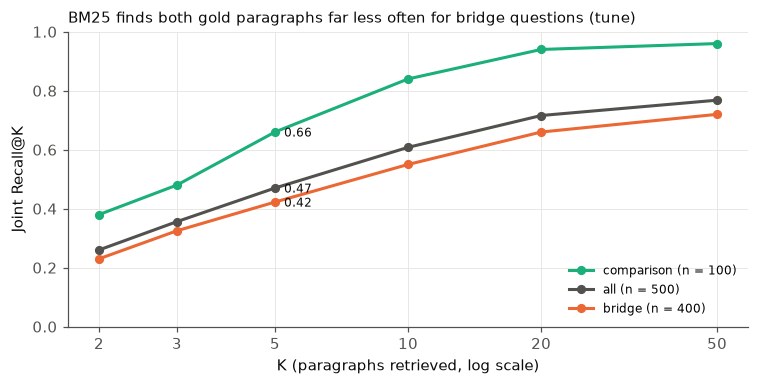

In [3]:
KS = (2, 3, 5, 10, 20, 50)
rows = pd.DataFrame(ret.values())
curve = []
for name, sub in [("all", rows), ("bridge", rows[rows.type == "bridge"]), ("comparison", rows[rows.type == "comparison"])]:
    for k in KS:
        curve.append({"subset": name, "n": len(sub), "K": k, "recall": sub[f"recall@{k}"].mean(),
                      "joint_recall": sub[f"joint_recall@{k}"].mean(),
                      "joint_recall_title": sub[f"title_joint_recall@{k}"].mean()})
curve = pd.DataFrame(curve)
display(curve.pivot(index="K", columns="subset", values=["recall", "joint_recall"]).round(3))
diff = (curve.joint_recall_title - curve.joint_recall).abs().max()
print(f"largest exact vs title-only difference in joint recall: {diff:.3f}")

fig, ax = plt.subplots(figsize=(7, 3.6))
for name, color in [("comparison", AQUA), ("all", MUTED), ("bridge", ORANGE)]:
    c = curve[curve.subset == name]
    ax.plot(c.K, c.joint_recall, marker="o", ms=5, lw=2, color=color, label=f"{name} (n = {c.n.iloc[0]})")
    ax.annotate(f"{c.joint_recall.iloc[2]:.2f}", (5, c.joint_recall.iloc[2]), textcoords="offset points",
                xytext=(6, -3), fontsize=8, color=INK)
ax.set_xscale("log")
ax.set_xticks(KS, [str(k) for k in KS])
ax.minorticks_off()
ax.set_ylim(0, 1)
ax.set_xlabel("K (paragraphs retrieved, log scale)")
ax.set_ylabel("Joint Recall@K")
ax.set_title("BM25 finds both gold paragraphs far less often for bridge questions (tune)", fontsize=10, loc="left", color=INK)
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

Comparison questions reach Joint Recall 0.84 at K = 10; bridge questions need K = 50 to
get to 0.72. Title-only and exact matching differ by at most 0.010, so the duplicated
titles barely affect retrieval scores on `tune`.

## 3. The two retrieval predictions (preregistered H1-a and H1-b)

- **H1-a:** for bridge questions, BM25 retrieves the second-hop paragraph less often than
  the first, with Recall@5 lower by at least 0.10. It is estimated over the bridge
  questions whose hop order the Phase 0 rule determines, as a paired difference.
- **H1-b:** Joint Recall@5 is higher for comparison questions than for bridge questions,
  estimated as an unpaired difference with resampling within each type.

In [4]:
ids = data.doc_id_of()
hop1, hop2, excluded = {}, {}, []
for q in tune:
    if q.type != "bridge":
        continue
    ch = hops.chain(q, tune_ctx[q.qid])
    if not ch.determined:
        excluded.append(q.qid)
        continue
    top5, gold = set(ret[q.qid]["ranked"][:5]), dict(q.gold)
    hop1[q.qid] = float(ids[(ch.first, gold[ch.first])] in top5)
    hop2[q.qid] = float(ids[(ch.second, gold[ch.second])] in top5)
h1a = metrics.paired_bootstrap(hop1, hop2)
print(f"H1-a  nominal bridge sample 400; eligible {len(hop1)}; excluded as undetermined {len(excluded)}")
print(f"      hit@5  hop 1 {np.mean(list(hop1.values())):.3f}   hop 2 {np.mean(list(hop2.values())):.3f}")
print(f"      hop 1 - hop 2 = {h1a['delta']:+.3f}  95% CI [{h1a['ci_low']:+.3f}, {h1a['ci_high']:+.3f}]  "
      f"(prediction: at least +0.10) -> {'holds' if h1a['ci_low'] >= 0.10 else 'not shown'}")

jr5 = {t: np.array([ret[q.qid]["joint_recall@5"] for q in tune if q.type == t]) for t in ("bridge", "comparison")}
rng = np.random.default_rng(0)
boot = np.array([rng.choice(jr5["comparison"], jr5["comparison"].size).mean()
                 - rng.choice(jr5["bridge"], jr5["bridge"].size).mean() for _ in range(10_000)])
d = jr5["comparison"].mean() - jr5["bridge"].mean()
print(f"\nH1-b  Joint Recall@5  comparison {jr5['comparison'].mean():.3f} (n = {jr5['comparison'].size})   "
      f"bridge {jr5['bridge'].mean():.3f} (n = {jr5['bridge'].size})")
print(f"      comparison - bridge = {d:+.3f}  95% CI [{np.percentile(boot, 2.5):+.3f}, {np.percentile(boot, 97.5):+.3f}]  "
      f"-> {'holds' if np.percentile(boot, 2.5) > 0 else 'not shown'}")

H1-a  nominal bridge sample 400; eligible 392; excluded as undetermined 8
      hit@5  hop 1 0.839   hop 2 0.523
      hop 1 - hop 2 = +0.316  95% CI [+0.253, +0.380]  (prediction: at least +0.10) -> holds



H1-b  Joint Recall@5  comparison 0.660 (n = 100)   bridge 0.422 (n = 400)
      comparison - bridge = +0.238  95% CI [+0.130, +0.340]  -> holds


Both predictions hold, and H1-a holds by a wide margin: the second-hop paragraph reaches
the top 5 for about half of the bridge questions (0.52), against 0.84 for the first hop.
The whole interval for the gap, [+0.25, +0.38], lies above the predicted 0.10. BM25's
multi-hop weakness is therefore specifically the hop the question does not name: when
Joint Recall fails for a bridge question, it is mostly the second hop that is missing.
Comparison questions, which name both entities, reach Joint Recall@5 of 0.66 against 0.42
for bridge questions.

## 4. Choosing K (`dev`, with the LLM)

The selected BM25 feeds the top K paragraphs to `qwen2.5:7b` with the frozen answer
prompt (`answer_v2`), for K ∈ {3, 5, 10}. The preregistered rule picks K by answer F1
over all 100 `dev` questions: the plateau is every K within 0.02 of the best, and the
first plateau member in the order 5, 3, 10 is selected. At n = 100 the interval on a
paired F1 difference is about ±0.07, so this is a coarse, cost-aware choice.

In [5]:
import scoring

dev = data.load_split("dev")
qd = {q.qid: q for q in dev}
runs = {name: read_jsonl(f"results/dev/{name}.jsonl") for name in ("bm25_k3", "bm25_k5", "bm25_k10", "closed_book", "oracle")}
for name, recs in runs.items():
    assert [r["qid"] for r in recs] == [q.qid for q in dev], name
scores = {name: [scoring.score(qd[r["qid"]], r, evidence=(name != "closed_book")) for r in recs]
          for name, recs in runs.items()}

rows = []
for k in (3, 5, 10):
    name = f"bm25_k{k}"
    f1 = metrics.mean_ci([s["f1"] for s in scores[name]])
    rows.append({"K": k, "F1": f1["mean"], "F1 95% CI": f"[{f1['ci_low']:.3f}, {f1['ci_high']:.3f}]",
                 "EM": np.mean([s["em"] for s in scores[name]]),
                 "Joint Recall (context)": np.mean([s["ctx_joint_recall"] for s in scores[name]]),
                 "mean prompt tokens": np.mean([r["llm"]["prompt_tokens"] for r in runs[name]]),
                 "median LLM s": np.median([r["llm"]["wall_s"] for r in runs[name]])})
kt = pd.DataFrame(rows).set_index("K")
best = kt.F1.max()
kt["in plateau"] = kt.F1 >= best - 0.02
selected_k = next(k for k in (5, 3, 10) if kt.loc[k, "in plateau"])
display(kt.round(3))
print(f"best F1 {best:.3f}; plateau: {list(kt.index[kt['in plateau']])}; selected K = {selected_k}")
for a, b in ((10, 5), (10, 3), (3, 5)):
    r = metrics.paired_bootstrap({s["qid"]: s["f1"] for s in scores[f"bm25_k{a}"]},
                                 {s["qid"]: s["f1"] for s in scores[f"bm25_k{b}"]})
    print(f"F1 K={a} - K={b}: {r['delta']:+.3f}  95% CI [{r['ci_low']:+.3f}, {r['ci_high']:+.3f}]")

,F1,F1 95% CI,EM,Joint Recall (context),mean prompt tokens,median LLM s,in plateau
K,,,,,,,
3,0.480,"[0.389, 0.571]",0.39,0.32,667.05,7.730,False
5,0.454,"[0.363, 0.546]",0.36,0.46,945.73,14.647,False
10,0.525,"[0.436, 0.612]",0.41,0.62,1715.73,20.634,True


best F1 0.525; plateau: [10]; selected K = 10
F1 K=10 - K=5: +0.071  95% CI [+0.007, +0.138]
F1 K=10 - K=3: +0.045  95% CI [-0.028, +0.120]
F1 K=3 - K=5: +0.026  95% CI [-0.042, +0.092]


Only K = 10 is inside the plateau, so K = 10 is selected, even though K = 5 was the
preferred default. The K = 10 minus K = 5 interval excludes zero; against K = 3 it does
not. The price is context: 10 paragraphs mean about 2.6 times the prompt tokens of 3 and
roughly 2.7 times the median LLM time.

## 5. The baseline at K = 10 (`dev`, n = 100)

Every question-level metric has a 95% bootstrap interval. "Context" metrics describe the
paragraphs actually shown to the LLM. The incomplete-gold-evidence proxy is the share of
outputs whose citations miss at least one gold paragraph; it is not proof that an answer
is unsupported.

In [6]:
BASE = "bm25_k10"
LABELS = {"em": "EM", "f1": "answer F1", "ctx_recall": "context Recall", "ctx_joint_recall": "context Joint Recall",
          "sp_strict_f1": "evidence F1 (strict)", "sp_strict_prec": "evidence precision (strict)",
          "sp_strict_recall": "evidence recall (strict)", "sp_official_f1": "evidence F1 (official-compatible)",
          "joint_official_f1": "joint F1 (official)", "supported": "supported rate",
          "has_citations": "citation coverage", "all_valid_citations": "all citations valid",
          "incomplete_gold_evidence": "incomplete-gold-evidence proxy"}


def profile(sc):
    out = {}
    for subset, part in (("all", sc), ("bridge", [s for s in sc if s["type"] == "bridge"]),
                         ("comparison", [s for s in sc if s["type"] == "comparison"])):
        summ = scoring.summarize(part, names=LABELS)
        out[f"{subset} (n={len(part)})"] = {LABELS[k]: f"{v['mean']:.3f} [{v['ci_low']:.2f}, {v['ci_high']:.2f}]"
                                           for k, v in summ.items()}
    return pd.DataFrame(out)


display(profile(scores[BASE]))
b = runs[BASE]
cit = metrics.aggregate_citations([metrics.citation_validity([tuple(c) for c in r["citations"]],
                                                             dict(zip(r["displayed"], r["displayed_sentences"]))) for r in b])
ans = metrics.answered_f1({s["qid"]: s["f1"] for s in scores[BASE]}, {s["qid"]: bool(s["supported"]) for s in scores[BASE]})
print(f"F1 on answered (supported = true): {ans['f1_answered']:.3f} over n = {ans['n_answered']}; "
      f"abstention rate {1 - ans['n_answered'] / len(b):.2f}")
print(f"per-citation validity {cit['per_citation_validity']:.3f} over {cit['n_citations']} citations; coverage {cit['coverage']:.2f}")
flags = pd.Series([f for s in scores[BASE] for f in s["answer_flags"]]).value_counts().to_dict()
print(f"schema errors {sum(r['schema_error'] for r in b)}; answer flags {flags or 'none'}; "
      f"overflow drops {sum(r['overflow_dropped'] for r in b)}")
lat = metrics.latency_stats([r["llm"]["wall_s"] for r in b])
rl = metrics.latency_stats([r["retrieval_s"] for r in b])
print(f"LLM: 1 call per question; prompt tokens mean {np.mean([r['llm']['prompt_tokens'] for r in b]):.0f}, "
      f"output tokens mean {np.mean([r['llm']['output_tokens'] for r in b]):.0f} "
      f"(rationale {np.mean([r['rationale_tokens'] for r in b]):.0f}); "
      f"wall p50 {lat['p50_s']:.1f} s, p95 {lat['p95_s']:.1f} s; total {sum(r['llm']['wall_s'] for r in b) / 60:.1f} min")
print(f"retrieval: 1 call per question; p50 {rl['p50_s'] * 1000:.1f} ms, p95 {rl['p95_s'] * 1000:.1f} ms")

,all (n=100),bridge (n=80),comparison (n=20)
EM,"0.410 [0.32, 0.50]","0.388 [0.29, 0.50]","0.500 [0.30, 0.70]"
answer F1,"0.525 [0.44, 0.61]","0.486 [0.39, 0.59]","0.680 [0.50, 0.85]"
context Recall,"0.795 [0.74, 0.85]","0.750 [0.69, 0.81]","0.975 [0.93, 1.00]"
context Joint Recall,"0.620 [0.52, 0.71]","0.537 [0.42, 0.65]","0.950 [0.85, 1.00]"
evidence F1 (strict),"0.327 [0.26, 0.39]","0.270 [0.20, 0.34]","0.553 [0.40, 0.71]"
evidence precision (strict),"0.415 [0.33, 0.50]","0.375 [0.29, 0.47]","0.575 [0.42, 0.73]"
evidence recall (strict),"0.297 [0.24, 0.36]","0.234 [0.17, 0.30]","0.550 [0.39, 0.72]"
evidence F1 (official-compatible),"0.327 [0.26, 0.39]","0.270 [0.20, 0.34]","0.553 [0.40, 0.71]"
joint F1 (official),"0.245 [0.18, 0.31]","0.204 [0.14, 0.27]","0.408 [0.23, 0.60]"
supported rate,"0.750 [0.66, 0.83]","0.700 [0.60, 0.80]","0.950 [0.85, 1.00]"


F1 on answered (supported = true): 0.673 over n = 75; abstention rate 0.25
per-citation validity 0.944 over 160 citations; coverage 0.91
schema errors 0; answer flags none; overflow drops 0
LLM: 1 call per question; prompt tokens mean 1716, output tokens mean 96 (rationale 47); wall p50 20.6 s, p95 26.5 s; total 34.6 min
retrieval: 1 call per question; p50 0.7 ms, p95 1.4 ms


On bridge questions, both gold paragraphs reach the context only 54% of the time (95% on
comparison questions), and answer F1 follows: 0.49 against 0.68. Evidence recall is low
for both types: the model cites 1.6 sentences per question on average, fewer than the
supporting facts a question has, so it cites a sentence that suffices rather than the
whole chain. Strict and official-compatible evidence scores coincide on `dev` (no
duplicated title is involved). There were no schema errors, no flagged answers and no
overflow drops.

## 6. Reference rows: closed-book and oracle (H1-d)

- **Closed-book:** the same LLM with no paragraphs; this is the answer to "why not just
  ask the LLM?". Its `supported` flag is self-reported confidence, so it is reported as
  a low-confidence rate and F1 when confident, and is excluded from evidence comparisons.
- **Oracle:** the two gold paragraphs only. It is a **gold-context reader reference**
  (an approximate reader ceiling), not a guaranteed ceiling: its shortfall from 1 can come
  from reader errors, annotation noise, answer granularity or metric mismatch.
- **H1-d:** F1 is ordered closed-book < baseline < oracle, and the oracle stays below 1.

In [7]:
f1 = {name: {s["qid"]: s["f1"] for s in scores[name]} for name in ("closed_book", BASE, "oracle")}
ref = []
for name in ("closed_book", BASE, "oracle"):
    c = metrics.mean_ci(list(f1[name].values()))
    em = metrics.mean_ci([s["em"] for s in scores[name]])
    ref.append({"system": name, "F1": f"{c['mean']:.3f} [{c['ci_low']:.2f}, {c['ci_high']:.2f}]",
                "EM": f"{em['mean']:.3f} [{em['ci_low']:.2f}, {em['ci_high']:.2f}]",
                "prompt tokens": np.mean([r["llm"]["prompt_tokens"] for r in runs[name]]),
                "median LLM s": np.median([r["llm"]["wall_s"] for r in runs[name]])})
display(pd.DataFrame(ref).set_index("system").round(1))

cb = {s["qid"]: bool(s["supported"]) for s in scores["closed_book"]}
conf = metrics.answered_f1(f1["closed_book"], cb)
print(f"closed-book: low-confidence rate {1 - conf['n_answered'] / 100:.2f}; "
      f"F1 when confident {conf['f1_answered']:.3f} (n = {conf['n_answered']})")
for a, b_ in ((BASE, "closed_book"), ("oracle", BASE)):
    r = metrics.paired_bootstrap(f1[a], f1[b_])
    print(f"F1 {a} - {b_}: {r['delta']:+.3f}  95% CI [{r['ci_low']:+.3f}, {r['ci_high']:+.3f}]")
o = metrics.mean_ci(list(f1["oracle"].values()))
print(f"oracle F1 {o['mean']:.3f}, 95% CI upper bound {o['ci_high']:.3f} -> stays below 1: {o['ci_high'] < 1}")

,F1,EM,prompt tokens,median LLM s
system,,,,
closed_book,"0.224 [0.15, 0.30]","0.150 [0.08, 0.22]",205.6,5.0
bm25_k10,"0.525 [0.44, 0.61]","0.410 [0.32, 0.50]",1715.7,20.6
oracle,"0.744 [0.67, 0.82]","0.610 [0.51, 0.71]",522.2,10.3


closed-book: low-confidence rate 0.42; F1 when confident 0.355 (n = 58)
F1 bm25_k10 - closed_book: +0.301  95% CI [+0.209, +0.395]
F1 oracle - bm25_k10: +0.219  95% CI [+0.133, +0.307]
oracle F1 0.744, 95% CI upper bound 0.818 -> stays below 1: True


All three parts of H1-d hold. Retrieval is worth +0.30 F1 over the closed-book model.
Giving the reader the two gold paragraphs instead would add another +0.22, so retrieval
leaves a large, measurable gap. Even with gold paragraphs, the reader reaches only 0.74
F1. The closed-book model declares low confidence on 42% of questions and reaches F1 0.36
when it claims confidence: it knows some of Wikipedia, but it cannot show where from.

## 7. Failure taxonomy (automatic, all 100 `dev` questions) and H1-c

Each question gets an **evidence bucket**: which gold paragraphs reached the K = 10
context. Hop order uses the Phase 0 rule, and a bridge question whose hop order it leaves
undetermined is never assigned a hop. The **answer outcome** is correct (EM 1), partial
(EM 0, F1 ≥ 0.5) or wrong (F1 < 0.5).

**H1-c:** among answers with EM = 0, more than half are **retrieval-associated
failures**, with at least one gold paragraph missing. That is an association, not a
cause: retrieval and reading can both fail on the same question.

In [8]:
dev_ctx = data.load_contexts("dev")
chains = {q.qid: hops.chain(q, dev_ctx[q.qid]) for q in dev}
tax = pd.DataFrame([{"qid": s["qid"], "type": s["type"],
                     "bucket": hops.evidence_bucket(qd[s["qid"]], chains[s["qid"]], s["gold_in_context"]),
                     "outcome": s["outcome"], "em": s["em"], "f1": s["f1"],
                     "cites_all_gold": s["incomplete_gold_evidence"] == 0.0}
                    for s in scores[BASE]])
order = ["both", "only_hop1", "only_hop2", "only_one_hop_undetermined", "only_one_entity", "neither"]
ct = pd.crosstab(tax.bucket, tax.outcome).reindex(index=order, columns=["correct", "partial", "wrong"], fill_value=0)
ct["total"] = ct.sum(axis=1)
display(ct)
print("undetermined hop order among dev bridge questions:",
      sum(1 for q in dev if q.type == "bridge" and not chains[q.qid].determined))

fail = tax[tax.em == 0]
missing = (fail.bucket != "both").astype(float)
c = metrics.mean_ci(missing.tolist())
print(f"\nH1-c  EM = 0: {len(fail)} questions; retrieval-associated (a gold paragraph missing): "
      f"{int(missing.sum())} = {c['mean']:.2f}  95% CI [{c['ci_low']:.2f}, {c['ci_high']:.2f}]  "
      f"-> {'holds' if c['ci_low'] > 0.5 else ('not shown' if c['ci_high'] > 0.5 else 'contradicted')}")
correct = tax[tax.outcome == "correct"]
print(f"correct answers whose citations cover both gold paragraphs: {int(correct.cites_all_gold.sum())} of {len(correct)}")

outcome,correct,partial,wrong,total
bucket,,,,
both,35,13,14,62
only_hop1,5,2,21,28
only_hop2,1,0,4,5
only_one_hop_undetermined,0,0,1,1
only_one_entity,0,0,1,1
neither,0,1,2,3


undetermined hop order among dev bridge questions: 1

H1-c  EM = 0: 59 questions; retrieval-associated (a gold paragraph missing): 32 = 0.54  95% CI [0.41, 0.66]  -> not shown
correct answers whose citations cover both gold paragraphs: 22 of 41


H1-c is **not shown**: 32 of the 59 EM = 0 answers (0.54) had a gold paragraph missing,
but the interval [0.41, 0.66] includes one half. The breakdown is sharper than the share:

- **The missing paragraph is almost always the second hop.** 28 questions had only hop 1
  in context, and 21 of those were answered wrong. Only 5 had only hop 2, and 3 had
  neither.
- **Having both gold paragraphs is not enough.** 62 questions had both, and 27 of those
  were still answered partially or wrongly.
- **Correct answers often cite incompletely.** Only 22 of the 41 correct answers cite
  both gold paragraphs.

## 8. Manual labels for 25 failures

The sample is preregistered: EM = 0 questions at K = 10, sorted by id, and 25 positions
drawn with `numpy.random.default_rng(20260929).choice(..., replace=False)`. The sample is
unstratified. Each case gets one label, and the first rule that applies decides:

1. `label_error`: the gold answer or evidence is doubtful;
2. `granularity`: the prediction is substantively correct;
3. a retrieval label: required gold evidence is absent;
4. `reasoning`: both gold paragraphs are present;
5. `other`.

These are exploratory labels by one annotator, who knew the system's outputs. They are
neither blinded nor independent.

In [9]:
fail_ids = sorted(tax.loc[tax.em == 0, "qid"])
pick = np.random.default_rng(20260929).choice(len(fail_ids), size=min(25, len(fail_ids)), replace=False)
sample = sorted(fail_ids[i] for i in pick)
recs = {r["qid"]: r for r in runs[BASE]}
t_idx = tax.set_index("qid")
cases = pd.DataFrame([{"#": n, "qid": qid, "type": qd[qid].type, "bucket": t_idx.loc[qid, "bucket"],
                       "F1": round(t_idx.loc[qid, "f1"], 2), "gold": qd[qid].answer, "prediction": recs[qid]["output"]["answer"],
                       "question": qd[qid].question.strip()} for n, qid in enumerate(sample, 1)]).set_index("#")
print(f"population: {len(fail_ids)} EM = 0 questions; sample: {len(sample)}")
with pd.option_context("display.max_colwidth", 90, "display.width", 250):
    display(cases)

population: 59 EM = 0 questions; sample: 25


,qid,type,bucket,F1,gold,prediction,question
#,,,,,,,
1,5a7109e95542994082a3e4fa,bridge,both,0.50,"Tallaght, South Dublin",Tallaght,What town did Sean Robert Francis play in as part of the most successful club in the R...
2,5a722c2255429971e9dc932c,bridge,both,0.67,SM Lifestyle Cities,SM Lifestyle City,"What type of development, currently existing in Pasay, is currently being considered f..."
3,5a7698c2554299373536010d,bridge,only_hop1,0.00,Car and Driver,No data,What is the total circulation of the magazine that called Ohio State Route 78 one of t...
4,5a7b1c6b55429931da12c9ca,comparison,both,0.67,"John Douglas ""Johnny"" Edwards",Johnny Edwards,"Johnny Edwards and Ian Anderson are singers, who had joined the greater number of bands?"
5,5a7e782655429934daa2fc26,bridge,both,0.80,half a million acres,half a million,"How many acres did this plantation consist of, in which the Honourable The Irish Socie..."
6,5a7fb6625542994857a767cc,bridge,only_hop1,0.00,BAFTA Awards for Best Actress,Olympic,Ali Eren Balıkel started a restaurant which hosted a number of famous figures includin...
7,5a827e8455429940e5e1a8dd,bridge,only_hop1,0.00,My Gorgeous Life,Barry Humphries,Les Patterson Saves the World was a comedy film starring the author of which autobiogr...
8,5a849c1b5542997175ce1ef9,bridge,only_hop1,0.00,alt-right,atheist,What sort of activist is the author of The Irrational Atheist?
9,5a85cd295542997175ce202b,bridge,only_hop2,0.00,Athenion,Polycrates,Who was the military commander of the last active ruler of the Ptolemaic Kingdom of Eg...


In [10]:
# One label per case, first applicable rule in precedence order, each with its evidence.
MANUAL = {
    1: ("granularity", "'Tallaght' is the town; gold adds ', South Dublin'"),
    2: ("granularity", "'SM Lifestyle City' vs 'SM Lifestyle Cities' (number only)"),
    3: ("label_error", "question asks the magazine's total circulation (1.23 million); gold is the magazine's name"),
    4: ("granularity", "'Johnny Edwards' names the gold person; gold is his full name"),
    5: ("granularity", "'half a million' vs 'half a million acres'"),
    6: ("retrieval_hop2", "Helen Mirren paragraph absent; model guessed 'Olympic' from an unrelated paragraph"),
    7: ("retrieval_hop2", "Dame Edna Everage paragraph ('My Gorgeous Life') absent; model answered the author"),
    8: ("retrieval_hop2", "Vox Day paragraph ('alt-right activist') absent; model used another atheist activist"),
    9: ("retrieval_hop1", "Athenion paragraph absent; model named a different Ptolemaic commander"),
    10: ("reasoning", "rationale says Schlegel flew two missions, yet the answer is Frimout (one)"),
    11: ("granularity", "'Anandji' vs 'Anandji Virji Shah'"),
    12: ("reasoning", "national-team paragraph was shown; model answered Bødker's club"),
    13: ("granularity", "'American novelist' vs 'American'"),
    14: ("retrieval_hop2", "United Mine Workers paragraph (35,000 members) absent"),
    15: ("granularity", "'25 April 2017' vs '25 April'; more specific, same date"),
    16: ("other", "hop-1 sentence already states 1990 and the rationale says 1990, but the answer "
                  "field is 'goes to number one': the answer contradicts its own rationale"),
    17: ("granularity", "'1964-1974' vs '1964 to 1974'; normalisation joins the hyphenated years into one token, so F1 = 0"),
    18: ("retrieval_both", "neither gold paragraph retrieved"),
    19: ("label_error", "question asks a religion; gold 'Hindi' is a language (from 'Hindi cinema music composer')"),
    20: ("granularity", "'The Ring' vs '\"The Ring\" magazine'"),
    21: ("retrieval_hop2", "Brian Doyle-Murray paragraph ('older brother of ... Bill Murray') absent"),
    22: ("label_error", "ambiguous target: the corpus's Corey Dillon paragraph says he played for the Patriots "
                        "and is in the 10,000-yard club, so the prediction also fits the question"),
    23: ("granularity", "'8.7–9.2' is the range in the gold paragraph; gold keeps its lower end; F1 = 0 from tokenisation"),
    24: ("retrieval_entity", "American Dream (film) paragraph absent"),
    25: ("retrieval_hop2", "George Adamski paragraph ('Polish American citizen') absent; hop 1 names him but not the attribute"),
}
assert sorted(MANUAL) == list(cases.index)
cases["label"] = [MANUAL[n][0] for n in cases.index]
cases["evidence"] = [MANUAL[n][1] for n in cases.index]
with pd.option_context("display.max_colwidth", 120, "display.width", 250):
    display(cases[["type", "bucket", "F1", "label", "evidence"]])
counts = cases.label.value_counts()
print(counts.to_string())
retrieval_total = counts[[c for c in counts.index if c.startswith("retrieval")]].sum()
print(f"\nretrieval labels together: {retrieval_total} of 25")

,type,bucket,F1,label,evidence
#,,,,,
1,bridge,both,0.50,granularity,"'Tallaght' is the town; gold adds ', South Dublin'"
2,bridge,both,0.67,granularity,'SM Lifestyle City' vs 'SM Lifestyle Cities' (number only)
3,bridge,only_hop1,0.00,label_error,question asks the magazine's total circulation (1.23 million); gold is the magazine's name
4,comparison,both,0.67,granularity,'Johnny Edwards' names the gold person; gold is his full name
5,bridge,both,0.80,granularity,'half a million' vs 'half a million acres'
6,bridge,only_hop1,0.00,retrieval_hop2,Helen Mirren paragraph absent; model guessed 'Olympic' from an unrelated paragraph
7,bridge,only_hop1,0.00,retrieval_hop2,Dame Edna Everage paragraph ('My Gorgeous Life') absent; model answered the author
8,bridge,only_hop1,0.00,retrieval_hop2,Vox Day paragraph ('alt-right activist') absent; model used another atheist activist
9,bridge,only_hop2,0.00,retrieval_hop1,Athenion paragraph absent; model named a different Ptolemaic commander


label
granularity         10
retrieval_hop2       6
label_error          3
reasoning            2
retrieval_hop1       1
other                1
retrieval_both       1
retrieval_entity     1

retrieval labels together: 9 of 25


Reading the 25 failures:

- **Ten are right in substance** (`granularity`): a shorter or longer form of the gold
  answer, such as "Anandji" for "Anandji Virji Shah" or "American novelist" for
  "American". EM counts them as failures and F1 gives partial credit. Two score F1 = 0
  only because of tokenisation: "1964-1974" and "8.7–9.2".
- **Three are doubtful targets** (`label_error`): a "circulation" question whose gold is
  a magazine name, a "religion" question whose gold is a language, and a question that
  the prediction also answers correctly (Corey Dillon).
- **Nine are retrieval-associated,** and **six of them miss the second hop:** the
  paragraph about the entity that the first hop names, which the question does not.
- **Two are reasoning errors** with both gold paragraphs present, one of which contradicts
  its own rationale. One more (`other`) gives an answer contradicting its rationale even
  though the needed fact was in hop 1.

So, on this sample, the real failures of the baseline are mostly second-hop retrieval,
while a large share of EM = 0 comes from answer form and annotation noise. That is why
F1, and not EM, is the primary answer metric.

## 9. Summary

| `dev` (n = 100) | Closed-book | BM25 RAG (K = 10) | Oracle (gold paragraphs) |
|---|---|---|---|
| Answer F1 | 0.224 | 0.525 | 0.744 |
| Answer EM | 0.150 | 0.410 | 0.610 |
| Context Joint Recall | — | 0.620 | 1.000 |
| Evidence F1 (strict) | — | 0.327 | 0.549 |
| Median LLM time | 5.0 s | 20.6 s | 10.3 s |

- **BM25 selection (`tune`):** stemming, stop words removed, `k1 = 1.5`, `b = 0.75`.
  Joint Recall@10 is 0.61 overall: 0.84 for comparison questions and 0.55 for bridge.
- **H1-a holds:** the second hop reaches the top 5 for 0.52 of bridge questions against
  0.84 for the first hop, a gap of +0.32 [+0.25, +0.38].
- **H1-b holds:** comparison questions beat bridge questions on Joint Recall@5 by +0.24
  [+0.13, +0.34].
- **H1-c is not shown:** 0.54 [0.41, 0.66] of EM = 0 answers are retrieval-associated.
  Of the 33 bridge questions with exactly one gold paragraph missing and a determined hop
  order, 28 are missing the second hop.
- **H1-d holds:** F1 rises from closed-book (0.22) to BM25 RAG (0.53) to oracle (0.74).
  Both steps have intervals that exclude zero, and the oracle stays below 1.
- **K = 10 is selected** by the preregistered rule. It costs about 2.6 times the prompt
  tokens of K = 3.
- **What limits the baseline:** retrieving a paragraph that the question does not name
  but the first paragraph does. A single query with the question cannot ask for it.